<a href="https://colab.research.google.com/github/Domiclement/NEXAFRICA-CUSTOMER_CHURN_ANALYSIS/blob/main/Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CUSTOMER CHURN ANALYSIS**

WEEK 1: Business Understanding, Data Collection & Data Preparation

**Objective**

Understand the customer churn problem, explore the dataset, and prepare the data for analysis.

**Task 1: To Understand the Business Problem**

Customer churn refers to the phenomenon where customers discontinue their relationship or subscription with a company or service provider. It represents the rate at which customers stop using a company's products or services within a specific period. Churn is an important metric for businesses as it directly impacts revenue, growth, and customer retention.

Understanding customer churn is crucial for businesses to identify patterns, factors, and indicators that contribute to customer attrition. By analyzing churn behavior and its associated features, companies can develop strategies to retain existing customers, improve customer satisfaction, and reduce customer turnover. Predictive modeling techniques can also be applied to forecast and proactively address potential churn, enabling companies to take proactive measures to retain at-risk customers.



**Problem Statement**

The objective of this project is to develop a Machine Learning classification model that predicts
whether a customer is likely to churn based on demographic information, account details,
subscription information, service usage, contract type, tenure, and billing information.

Task 2: Obtain and Load the Dataset

In [124]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [125]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Dataset path:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset path: /kaggle/input/telco-customer-churn


In [126]:
print(os.listdir(path))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [127]:
file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [128]:
df.shape

(7043, 21)

In [129]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [130]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [132]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [133]:
data_dictionary = {
    "Feature": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "Contract",
        "MonthlyCharges",
        "TotalCharges",
        "PaymentMethod",
        "Churn"
    ],

    "Description": [
        "Unique customer identifier",
        "Customer's gender",
        "Whether the customer is a senior citizen",
        "Whether the customer has a partner",
        "Whether the customer has dependents",
        "Number of months the customer has stayed with the company",
        "Customer's contract type",
        "Monthly amount charged to the customer",
        "Total amount charged to the customer",
        "Customer's payment method",
        "Whether the customer left the company"
    ],

    "Type": [
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Numerical",
        "Categorical",
        "Numerical",
        "Numerical",
        "Categorical",
        "Target"
    ]
}

In [134]:
dictionary_df = pd.DataFrame(data_dictionary)

dictionary_df

,Feature,Description,Type
0,customerID,Unique customer identifier,Categorical
1,gender,Customer's gender,Categorical
2,SeniorCitizen,Whether the customer is a senior citizen,Categorical
3,Partner,Whether the customer has a partner,Categorical
4,Dependents,Whether the customer has dependents,Categorical
5,tenure,Number of months the customer has stayed with ...,Numerical
6,Contract,Customer's contract type,Categorical
7,MonthlyCharges,Monthly amount charged to the customer,Numerical
8,TotalCharges,Total amount charged to the customer,Numerical
9,PaymentMethod,Customer's payment method,Categorical


In [135]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [136]:
df.duplicated().sum()

np.int64(0)

In [137]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [138]:
# Drop rows with NaN values that were introduced during TotalCharges conversion
df.dropna(inplace=True)

In [139]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [140]:
df['Churn'].value_counts()

,count
Churn,
No,5163
Yes,1869


In [141]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.421502
Yes,26.578498


# Exploratory Data Analysis & Feature Engineering
Objective is to
Understand the dataset, identify important patterns, and prepare meaningful features for machine
learning models.

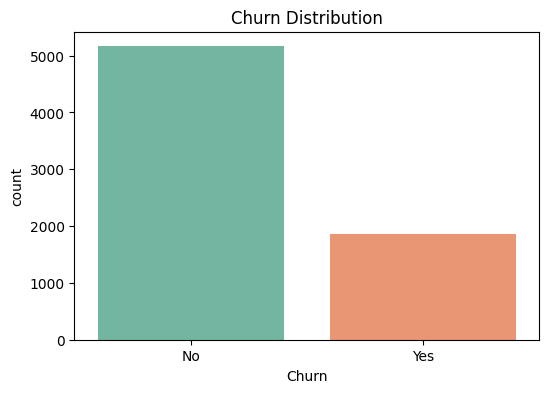

In [142]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Churn Distribution')
plt.show()

**Churn By Contract Type**

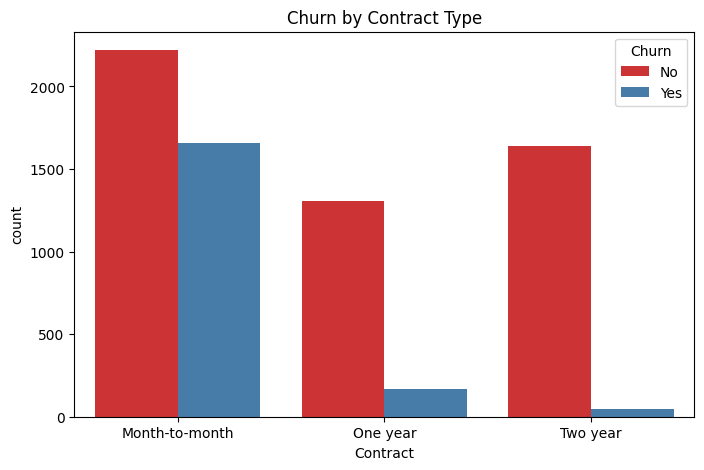

In [143]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')
plt.title('Churn by Contract Type')
plt.show()

**Monthly Charges vs Churn**

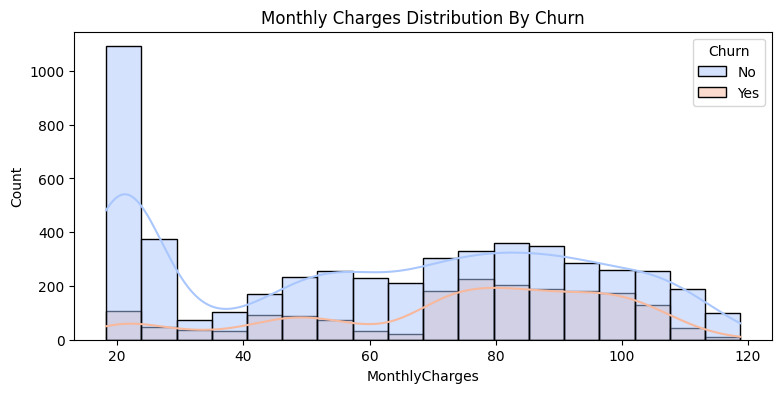

In [144]:
plt.figure(figsize=(9,4))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, palette='coolwarm')
plt.title('Monthly Charges Distribution By Churn')
plt.show()

**Tenure vs Churn**

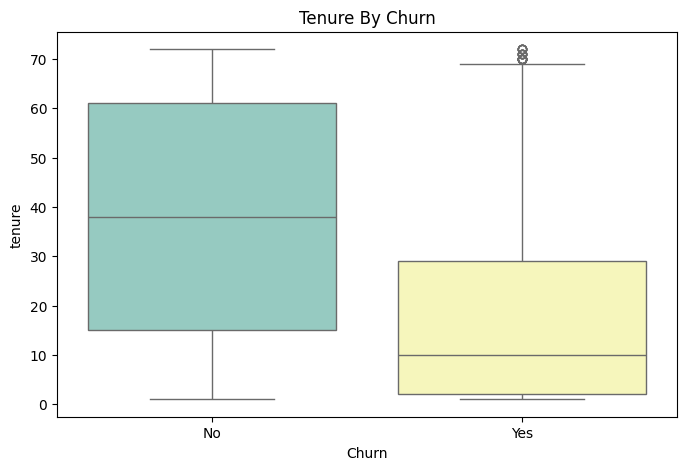

In [145]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Churn', y="tenure", hue='Churn', palette='Set3', legend=False)
plt.title('Tenure By Churn')
plt.show()

**Corelation & Features Importance**

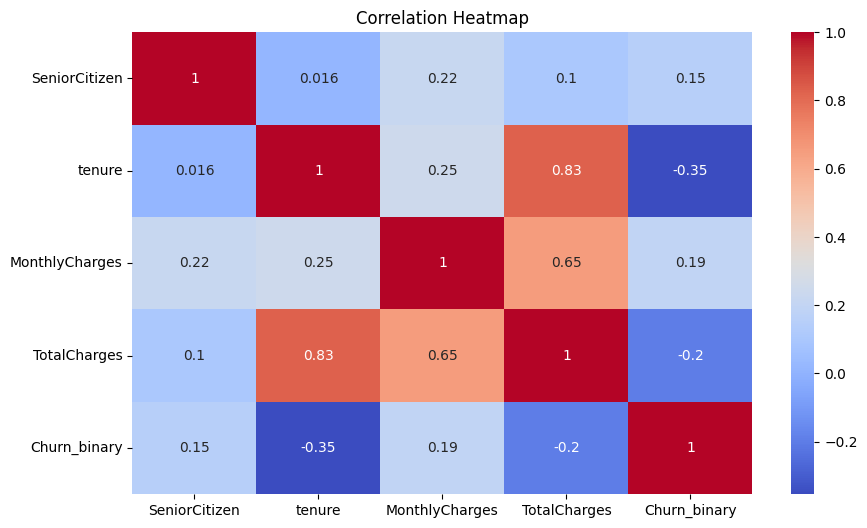

In [146]:
#Encode Churn Binary

df['Churn_binary'] = df['Churn'].map({'Yes':1, 'No':0})

#Numerical Corelation Heatmap

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Insightful Observation**

In [147]:
# High Risk Churn Segment
high_churn = df[(df['Churn'] == 'Yes') & (df['Contract'] == 'Month-to-month')]

#Insight No.1 - What % of Churn comes from Month-to-month
percent_monthly = len(high_churn)/len(df[df['Churn'] == 'Yes'])*100
print(f"Insight: {percent_monthly:.2f} % of all churned customers were on Month-to-month contract")

#Insight No.2 - Senior Citizen more likely to churn
senior_churn_rate = df[df['SeniorCitizen']==1]['Churn_binary'].mean()
non_senior_churn_rate = df[df['SeniorCitizen'] == 0]['Churn_binary'].mean()
print(f"Insight: Senior Citizen Churn Rate = {senior_churn_rate: .2f}")
print(f"Insight: Non-Senior Citizen Churn Rate = {non_senior_churn_rate: .2f}")

Insight: 88.55 % of all churned customers were on Month-to-month contract
Insight: Senior Citizen Churn Rate =  0.42
Insight: Non-Senior Citizen Churn Rate =  0.24


In [148]:
df =df.drop('customerID', axis=1)

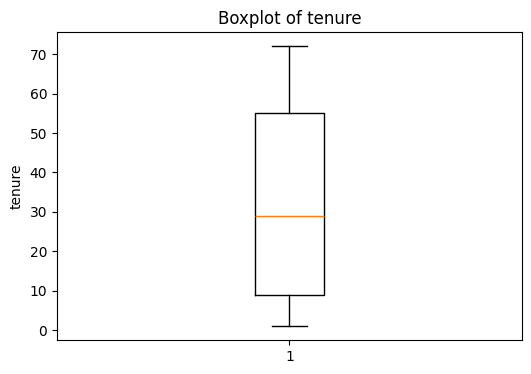

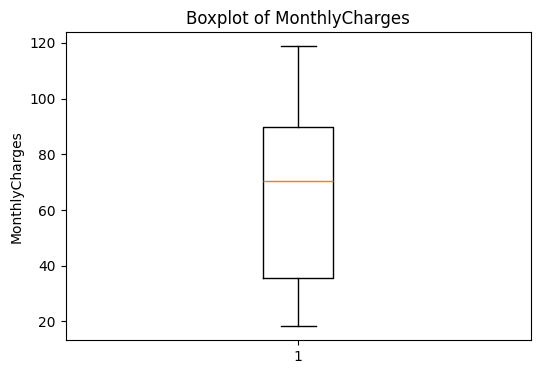

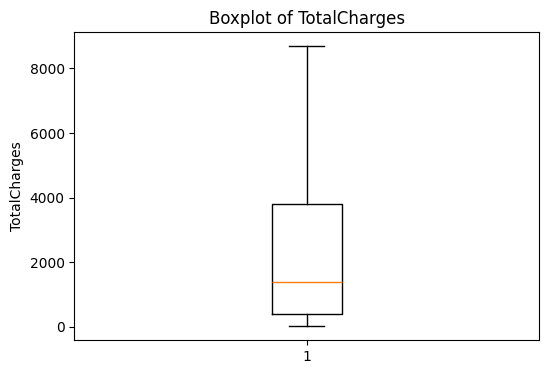

In [149]:
col = ['tenure', 'MonthlyCharges', 'TotalCharges']
for column in col:
  plt.figure(figsize=(6,4))
  plt.boxplot(X[column].dropna())
  plt.title(f'Boxplot of {column}')
  plt.ylabel(column)
  plt.show()

**Label Encoder**

In [150]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0


In [151]:
cols = [col for col in df.columns if df[col].dtype == 'object']
cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [152]:
for col in cols:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
df.head(2)

X = df.drop(['Churn', 'Churn_binary'], axis = 1)
y = df['Churn']

In [153]:
# Check the dimensions
print('Features shape:', X.shape)
print('Target shape:', y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [154]:
#Check the target distribution
print(y.value_counts())
print(y.value_counts(normalize=True)*100)

Churn
0    5163
1    1869
Name: count, dtype: int64
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64


# WEEK 3: MACHINE LEARNING MODEL DEVELOPMENT

**Task 1: Prepare Training and Testing Data**

In [155]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state=42,
    stratify=y
)

In [156]:
# Verify that the class distribution has been preserved

print('Training distribution:')
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

Testing distribution:
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


**Task 2: Logistic Regression Baseline**

In [157]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [158]:
logistic_model = LogisticRegression(random_state=42, max_iter = 1000)
logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

In [159]:
# Evaluate the Logistic Regression model
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_pred_logistic)

print(f"Logistic Regression Accuracy: {accuracy_logistic:.4f}")
print(f"Logistic Regression Precision: {precision_logistic:.4f}")
print(f"Logistic Regression Recall: {recall_logistic:.4f}")
print(f"Logistic Regression F1-Score: {f1_logistic:.4f}")
print(f"Logistic Regression ROC AUC: {roc_auc_logistic:.4f}")

# Confusion Matrix
conf_matrix_logistic = confusion_matrix(y_test, y_pred_logistic)
print("\nConfusion Matrix:")
print(conf_matrix_logistic)

# Classification Report
class_report_logistic = classification_report(y_test, y_pred_logistic)
print("\nClassification Report:")
print(class_report_logistic)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate the Decision Tree model
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.4f}")
print(f"Decision Tree Precision: {precision_dt:.4f}")
print(f"Decision Tree Recall: {recall_dt:.4f}")
print(f"Decision Tree F1-Score: {f1_dt:.4f}")
print(f"Decision Tree ROC AUC: {roc_auc_dt:.4f}")

# Confusion Matrix
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
print("\nConfusion Matrix:")
print(conf_matrix_dt)

# Classification Report
class_report_dt = classification_report(y_test, y_pred_dt)
print("\nClassification Report:")
print(class_report_dt)

Logistic Regression Accuracy: 0.7960
Logistic Regression Precision: 0.6314
Logistic Regression Recall: 0.5588
Logistic Regression F1-Score: 0.5929
Logistic Regression ROC AUC: 0.7204

Confusion Matrix:
[[911 122]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1033
           1       0.63      0.56      0.59       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407

Decision Tree Accuracy: 0.6951
Decision Tree Precision: 0.4311
Decision Tree Recall: 0.4599
Decision Tree F1-Score: 0.4450
Decision Tree ROC AUC: 0.6201

Confusion Matrix:
[[806 227]
 [202 172]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.78      0.79      1033
           1       0.43      0.46      0.45       374

    accuracy                           0.

**Task 3: Training Additional Models**

**Decision Tree**

In [160]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate the Decision Tree model
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.4f}")
print(f"Decision Tree Precision: {precision_dt:.4f}")
print(f"Decision Tree Recall: {recall_dt:.4f}")
print(f"Decision Tree F1-Score: {f1_dt:.4f}")
print(f"Decision Tree ROC AUC: {roc_auc_dt:.4f}")

# Confusion Matrix
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
print("\nConfusion Matrix:")
print(conf_matrix_dt)

# Classification Report
class_report_dt = classification_report(y_test, y_pred_dt)
print("\nClassification Report:")
print(class_report_dt)

Decision Tree Accuracy: 0.6951
Decision Tree Precision: 0.4311
Decision Tree Recall: 0.4599
Decision Tree F1-Score: 0.4450
Decision Tree ROC AUC: 0.6201

Confusion Matrix:
[[806 227]
 [202 172]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.78      0.79      1033
           1       0.43      0.46      0.45       374

    accuracy                           0.70      1407
   macro avg       0.62      0.62      0.62      1407
weighted avg       0.70      0.70      0.70      1407



In [161]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate the Decision Tree model
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.4f}")
print(f"Decision Tree Precision: {precision_dt:.4f}")
print(f"Decision Tree Recall: {recall_dt:.4f}")
print(f"Decision Tree F1-Score: {f1_dt:.4f}")
print(f"Decision Tree ROC AUC: {roc_auc_dt:.4f}")

# Confusion Matrix
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
print("\nConfusion Matrix:")
print(conf_matrix_dt)

# Classification Report
class_report_dt = classification_report(y_test, y_pred_dt)
print("\nClassification Report:")
print(class_report_dt)

Decision Tree Accuracy: 0.6951
Decision Tree Precision: 0.4311
Decision Tree Recall: 0.4599
Decision Tree F1-Score: 0.4450
Decision Tree ROC AUC: 0.6201

Confusion Matrix:
[[806 227]
 [202 172]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.78      0.79      1033
           1       0.43      0.46      0.45       374

    accuracy                           0.70      1407
   macro avg       0.62      0.62      0.62      1407
weighted avg       0.70      0.70      0.70      1407



**XGBoost Classifier**

In [162]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)

# Evaluate the XGBoost model
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_pred_xgb)

print(f"XGBoost Accuracy: {accuracy_xgb:.4f}")
print(f"XGBoost Precision: {precision_xgb:.4f}")
print(f"XGBoost Recall: {recall_xgb:.4f}")
print(f"XGBoost F1-Score: {f1_xgb:.4f}")
print(f"XGBoost ROC AUC: {roc_auc_xgb:.4f}")

# Confusion Matrix
conf_matrix_xgb = confusion_matrix(y_test, y_pred_xgb)
print("\nConfusion Matrix:")
print(conf_matrix_xgb)

# Classification Report
class_report_xgb = classification_report(y_test, y_pred_xgb)
print("\nClassification Report:")
print(class_report_xgb)

XGBoost Accuracy: 0.7647
XGBoost Precision: 0.5754
XGBoost Recall: 0.4385
XGBoost F1-Score: 0.4977
XGBoost ROC AUC: 0.6607

Confusion Matrix:
[[912 121]
 [210 164]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.85      1033
           1       0.58      0.44      0.50       374

    accuracy                           0.76      1407
   macro avg       0.69      0.66      0.67      1407
weighted avg       0.75      0.76      0.75      1407



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:23:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


**Random Forest Classifier**

In [163]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluate the Random Forest model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf:.4f}")
print(f"Random Forest Precision: {precision_rf:.4f}")
print(f"Random Forest Recall: {recall_rf:.4f}")
print(f"Random Forest F1-Score: {f1_rf:.4f}")
print(f"Random Forest ROC AUC: {roc_auc_rf:.4f}")

# Confusion Matrix
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)
print("\nConfusion Matrix:")
print(conf_matrix_rf)

# Classification Report
class_report_rf = classification_report(y_test, y_pred_rf)
print("\nClassification Report:")
print(class_report_rf)

Random Forest Accuracy: 0.7740
Random Forest Precision: 0.6102
Random Forest Recall: 0.4144
Random Forest F1-Score: 0.4936
Random Forest ROC AUC: 0.6593

Confusion Matrix:
[[934  99]
 [219 155]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.90      0.85      1033
           1       0.61      0.41      0.49       374

    accuracy                           0.77      1407
   macro avg       0.71      0.66      0.67      1407
weighted avg       0.76      0.77      0.76      1407



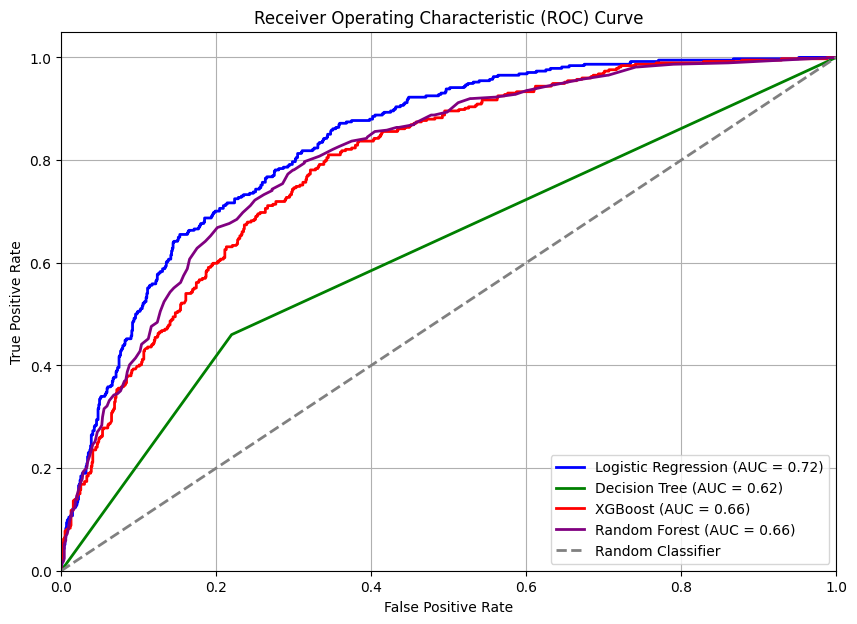

In [164]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve for Logistic Regression
fpr_logistic, tpr_logistic, _ = roc_curve(y_test, logistic_model.predict_proba(X_test_scaled)[:, 1])
roc_auc_logistic = roc_auc_score(y_test, y_pred_logistic)

# Calculate ROC curve for Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_model.predict_proba(X_test_scaled)[:, 1])
roc_auc_dt = roc_auc_score(y_test, y_pred_dt)

# Calculate ROC curve for XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_model.predict_proba(X_test_scaled)[:, 1])
roc_auc_xgb = roc_auc_score(y_test, y_pred_xgb)

# Calculate ROC curve for Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_model.predict_proba(X_test_scaled)[:, 1])
roc_auc_rf = roc_auc_score(y_test, y_pred_rf)

# Plotting the ROC curves
plt.figure(figsize=(10, 7))
plt.plot(fpr_logistic, tpr_logistic, color='blue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_logistic:.2f})')
plt.plot(fpr_dt, tpr_dt, color='green', lw=2, label=f'Decision Tree (AUC = {roc_auc_dt:.2f})')
plt.plot(fpr_xgb, tpr_xgb, color='red', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})')
plt.plot(fpr_rf, tpr_rf, color='purple', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

| Model               | Accuracy | Precision | Recall | F1-Score | ROC AUC |
|:--------------------|:---------|:----------|:-------|:---------|:--------|
| Logistic Regression | 0.7960   | 0.6314    | 0.5588 | 0.5929   | 0.7204  |
| Decision Tree       | 0.6951   | 0.4311    | 0.4599 | 0.4450   | 0.6201  |
| XGBoost             | 0.7647   | 0.5754    | 0.4385 | 0.4977   | 0.6607  |
| Random Forest       | 0.7740   | 0.6102    | 0.4144 | 0.4936   | 0.6593  |

## Initial Model Selection

The four classification models were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. Since the objective of this project is to identify customers who are likely to churn, the model selection was not based on accuracy alone. Particular attention was given to Precision, Recall, F1-Score, and ROC-AUC because they provide a better understanding of how effectively the models identify potential churners.

Based on the evaluation results, **Logistic Regression was selected as the initial model** for further consideration. It achieved the highest Accuracy (79.60%), Precision (63.14%), Recall (55.88%), F1-Score (59.29%), and ROC-AUC (72.04%) among the four models tested.

The Decision Tree produced the lowest overall performance, with an Accuracy of 69.51%, F1-Score of 44.50%, and ROC-AUC of 62.01%. XGBoost achieved an Accuracy of 76.47%, but its Recall (43.85%) and F1-Score (49.77%) were lower than those of Logistic Regression. Similarly, Random Forest achieved 77.40% Accuracy and 61.02% Precision, but its Recall (41.44%), F1-Score (49.36%), and ROC-AUC (65.93%) were lower than Logistic Regression.

Therefore, Logistic Regression provides the strongest overall baseline performance on the test set. Its relatively higher Recall indicates that it identifies a greater proportion of customers who actually churned, while its higher F1-Score demonstrates a better balance between Precision and Recall. Its ROC-AUC of 0.7204 also indicates better discrimination between churn and non-churn customers compared with the other models tested.

However, this should be considered an **initial model selection rather than a final conclusion**. Further steps such as hyperparameter tuning, class-imbalance handling, and classification-threshold optimization could potentially improve the model's ability to identify customers at risk of churn.
